# Pre-lab: forecasting the Premier League (COMPLETED)

People legally bet about 20 billion annualing on the English Premier League, and 1 billion per match on average. This is an astronomical sum of money. Perhaps we can data science it.

The EPL has 20 football teams play a total of 380 matches from August to May. It is Double Round-Robin Format: Every team plays each other team twice (home and away). The outcome of each match contributes to a team's point total:

- Win: 3 points
- Draw: 1 point
- Lose: 0 points
  
At the end of the season, the team with the most points wins the Premier League; if a tie, the winner is the one with the bigger difference between goals scored and goals conceded (if you need further tie-breaking in what follows, decide the winner at random). If you are one of the worst three teams (18th, 19th, 20th), you get kicked out of the Premier League and demoted to EFL Championship.

Your objective for this lab is: Predict which teams win the 2026-2027 Premier League, and which get relegated.


**Goal.** Use the Poisson likelihood to simulate the rest of the season to get title and relegation odds.




In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln

rng = np.random.default_rng(5030)

df = pd.read_parquet("data/premier.parquet")
df.head()

,date,offense,defense,home_away,goals
0,2015-08-08,Bournemouth,Aston Villa,Home,0
1,2015-08-08,Aston Villa,Bournemouth,Away,1
2,2015-08-08,Chelsea,Swansea,Home,2
3,2015-08-08,Swansea,Chelsea,Away,2
4,2015-08-08,Everton,Watford,Home,2


`premier.parquet` has every season from 2015-16 to 2025-26, two rows per match (one row for each team's goals). **In this pre-lab we only use last season, 2025-26** (380 matches, 760 rows). In Thursday's lab you'll use all of the seasons.

In [2]:
season = df[df["date"] >= "2025-08-01"].reset_index(drop=True)   # 2025-26 only
print(season["date"].min().date(), "to", season["date"].max().date(), "|", len(season) // 2, "matches")

2025-08-15 to 2026-05-24 | 380 matches


# 1. The Poisson likelihood

Start with the simplest possible model: every team, in every game, scores goals according to the **same** Poisson distribution,
$$
\text{pr}[X = x \mid \lambda] = \frac{e^{-\lambda}\lambda^x}{x!}.
$$



<div class="alert alert-info">

**1.** Compute $\hat\lambda$ for a single Poisson distribution, then plot its PMF next to the observed histogram of goals.

</div>

lambda-hat = 1.375 goals per team per game


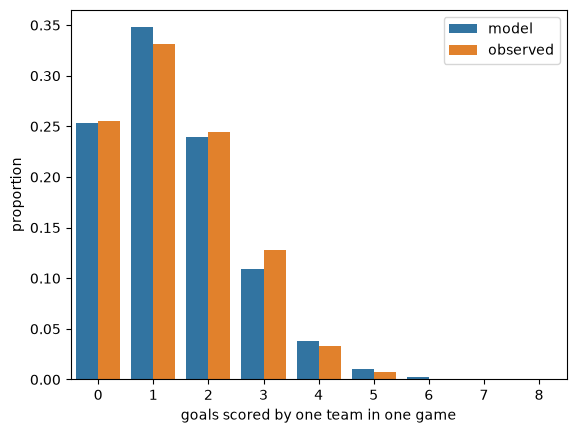

In [3]:
import seaborn as sns

lam_hat = season["goals"].mean()            # MLE for a single Poisson is the sample mean
print("lambda-hat =", round(lam_hat, 3), "goals per team per game")

ks = np.arange(0, 9)
model = stats.poisson.pmf(ks, lam_hat)
observed = season["goals"].value_counts(normalize=True).reindex(ks, fill_value=0).to_numpy()

#put them together in a long df for seaborn
naive_vs_data = pd.DataFrame({"x": ks, "model": model, "observed": observed})
naive_vs_data = pd.melt(naive_vs_data, id_vars="x", value_vars=["model", "observed"], var_name="mean")

sns.barplot(data=naive_vs_data, x="x", y="value", hue="mean")
plt.xlabel("goals scored by one team in one game")
plt.ylabel("proportion")
plt.legend()
plt.show()

**Answer.** $\hat\lambda = \bar x \approx 1.38$ goals per team per game. One Poisson matches the overall shape of the histogram well, but it treats every team as identical.

# 2. Parameterizing the mean

Every team is not the same, so it doesn't really make sense to fit a single Poisson distribution to our data. Let's parameterize $\lambda$ so it depends on the two teams playing in each game:

$$
\text{goals scored by A vs B} \sim \text{Poisson}(\lambda_{AB})
$$
$$
\log \lambda_{AB} = \text{offense}_A + \text{defense}_B
$$

and for the other row of the same game,
$$
\log \lambda_{BA} = \text{offense}_B + \text{defense}_A .
$$

**This is the log link.** We model $\log\lambda$, not $\lambda$, as a linear function of the coefficients: $\log\lambda_i = x_i\cdot\beta$, so $\lambda_i = e^{x_i\cdot\beta}$. In the notes we wrote $\lambda_i = x_i\cdot\beta$ directly (the *identity link*). We use the log link here because:

- **$\lambda$ is always positive.** 
- **It's the standard choice.** It's the default for Poisson regression in `statsmodels` and almost everywhere else.

**Note: For the lab on Thursday, you will also incorporate the `home_away` variable.**

### Design matrix

Each row of $X$ has a 1 in the column of the team on offense, and a 1 in the column of the team on defense. There is **no constant**. We keep all 20 offense columns and **drop one team's defense column** (Arsenal, first alphabetically), just like dropping a category for dummy variables. Otherwise the model isn't identified: adding the same number to every offense coefficient and subtracting it from every defense coefficient gives exactly the same $\lambda$'s, so the MLE isn't unique.

With Arsenal's defense as the baseline ($\text{defense}_{\text{Arsenal}} = 0$), $e^{\text{offense}_A}$ is team A's expected goals against Arsenal's defense, and $e^{\text{defense}_B}$ is how many times more goals team B concedes than Arsenal does.

In [4]:
def design_matrix(df, teams):
    off = pd.get_dummies(df["offense"]).reindex(columns=teams, fill_value=0).astype(float)
    dfn = pd.get_dummies(df["defense"]).reindex(columns=teams, fill_value=0).astype(float)
    # no constant: keep every offense column, drop the first team's (Arsenal's) defense column
    X = np.column_stack([off, dfn.iloc[:, 1:]])
    names = ["off_" + t for t in teams] + ["def_" + t for t in teams[1:]]
    return X, names

teams = sorted(season["offense"].unique())    # alphabetical, so the baseline is Arsenal
X, names = design_matrix(season, teams)
y = season["goals"].to_numpy()
print(X.shape)   # 760 rows, 20 + 19 = 39 columns

(760, 39)


### Log-likelihood and gradient

With $\lambda_i = e^{x_i\cdot\beta}$,
$$
L[y \mid X, \beta] = \sum_{i=1}^n \Big( -e^{x_i\cdot\beta} + y_i\, x_i\cdot\beta - \log(y_i!) \Big)
$$

<div class='alert alert-info'>

**2.** Use the design matrix and statsmodels to find $\lambda$ that maximize the log-likelihood. What does this mean?

</div>

In [5]:
import statsmodels.api as sm
fit = sm.GLM(y, X, family=sm.families.Poisson()).fit()

off = pd.Series(fit.params[:len(teams)], index=teams)                # offense_i
dfn = pd.Series(np.r_[0.0, fit.params[len(teams):]], index=teams)    # defense_j (Arsenal = 0)
ratings = pd.DataFrame({"offense": off, "defense": dfn})
ratings.sort_values("offense", ascending=False).round(2)

,offense,defense
Man City,0.05,0.27
Arsenal,-0.04,0.00
Man United,-0.05,0.62
Liverpool,-0.13,0.67
Bournemouth,-0.22,0.68
Chelsea,-0.22,0.64
Aston Villa,-0.26,0.58
Brentford,-0.27,0.64
Newcastle,-0.31,0.70
Brighton,-0.33,0.51


In [6]:
# What the MLE means: observed = expected for every column of X
lam_fit = fit.predict(X)                     # lambda-hat for every row
pd.DataFrame({
    "scored (actual)":   season.groupby("offense")["goals"].sum(),
    "scored (model)":    pd.Series(lam_fit).groupby(season["offense"].to_numpy()).sum(),
    "conceded (actual)": season.groupby("defense")["goals"].sum(),
    "conceded (model)":  pd.Series(lam_fit).groupby(season["defense"].to_numpy()).sum(),
}).round(1)

,scored (actual),scored (model),conceded (actual),conceded (model)
Arsenal,71,71.0,27,27.0
Aston Villa,56,56.0,49,49.0
Bournemouth,58,58.0,54,54.0
Brentford,55,55.0,52,52.0
Brighton,52,52.0,46,46.0
Burnley,38,38.0,75,75.0
Chelsea,58,58.0,52,52.0
Crystal Palace,41,41.0,51,51.0
Everton,47,47.0,50,50.0
Fulham,47,47.0,51,51.0


**Answer.** `statsmodels` finds the $\hat\beta$ (and so the $\hat\lambda_i = e^{x_i\cdot\hat\beta}$) that make the observed scores most likely: the MLE. At the maximum the gradient $X^\top(y - \hat\lambda)$ is zero, so for every column of $X$, **observed = expected**: each team's predicted goals scored and conceded add up exactly to its real totals (table above), even though no single game is predicted exactly.

Reading the ratings: $e^{\text{offense}_i}$ is team $i$'s expected goals against Arsenal's defense (Man City: $e^{0.05} \approx 1.05$; Wolves: $e^{-0.97} \approx 0.38$). $e^{\text{defense}_j}$ is how many times more goals $j$ concedes than Arsenal (Burnley: $e^{0.99} \approx 2.7$). Bigger offense is better; bigger defense is worse.

# 3. One match = two Poisson distributions

For a match between A and B we get two rates:
$$
\lambda_A = e^{\text{offense}_A + \text{defense}_B}, \qquad
\lambda_B = e^{\text{offense}_B + \text{defense}_A}
$$
If we assume the two teams' goals are independent, the probability of an exact scoreline is
$$
\text{pr}[A = a, B = b] = \text{pr}[A=a]\,\text{pr}[B=b].
$$

<div class='alert alert-info'>

**3.** What is the PMF of number of goals for teams A and B, when team A = "Arsenal" and team B = "Man City"? Which team is predicted to score more goals?

</div>

expected goals: Arsenal 1.25, Man City 1.05
P(Arsenal win) = 0.407 | P(draw) = 0.282 | P(Man City win) = 0.308


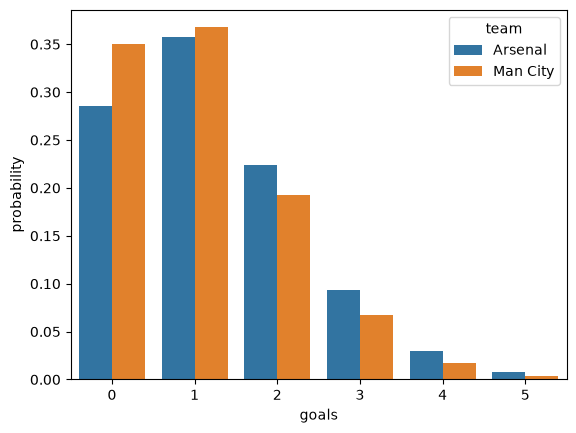

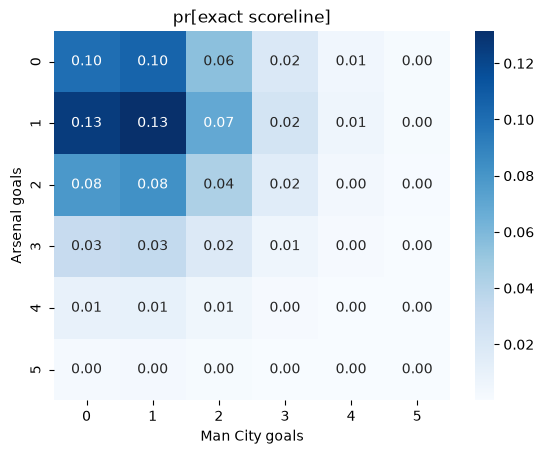

In [7]:
# hint: a nice way to get a PMF over two marginal distributions is to use
# grid = np.outer(stats.poisson.pmf(g, lam_a), stats.poisson.pmf(g, lam_b))

def rates(team_a, team_b):
    # expected goals for each side when team_a plays team_b
    lam_a = np.exp(off[team_a] + dfn[team_b])
    lam_b = np.exp(off[team_b] + dfn[team_a])
    return lam_a, lam_b

lam_a, lam_b = rates("Arsenal", "Man City")
print(f"expected goals: Arsenal {lam_a:.2f}, Man City {lam_b:.2f}")

g = np.arange(0, 6)
pmf = pd.DataFrame({"goals": g, "Arsenal": stats.poisson.pmf(g, lam_a), "Man City": stats.poisson.pmf(g, lam_b)})
grid = pd.DataFrame(np.outer(pmf["Arsenal"], pmf["Man City"]), index=g, columns=g)   # grid.loc[a, b] = pr[Arsenal = a, Man City = b]

print("P(Arsenal win) =", np.tril(grid, -1).sum().round(3),
      "| P(draw) =", np.trace(grid).round(3),
      "| P(Man City win) =", np.triu(grid, 1).sum().round(3))

# marginal PMFs, side by side
sns.barplot(data=pmf.melt(id_vars="goals", var_name="team", value_name="probability"), x="goals", y="probability", hue="team")
plt.show()

# joint PMF of the exact scoreline
sns.heatmap(grid, annot=True, fmt=".2f", cmap="Blues")
plt.ylabel("Arsenal goals"); plt.xlabel("Man City goals"); plt.title("pr[exact scoreline]")
plt.show()

In [11]:
grid

,0,1,2,3,4,5
0,0.100026,0.104995,0.055105,0.019281,0.005060,0.001062
1,0.125297,0.131522,0.069028,0.024152,0.006338,0.001331
2,0.078477,0.082375,0.043234,0.015127,0.003970,0.000833
3,0.032768,0.034396,0.018052,0.006316,0.001658,0.000348
4,0.010262,0.010771,0.005653,0.001978,0.000519,0.000109
5,0.002571,0.002699,0.001416,0.000496,0.000130,0.000027


**Answer.** Arsenal's goals are Poisson($\hat\lambda \approx 1.25$) and Man City's are Poisson($\hat\lambda \approx 1.05$). The joint PMF is the outer product of the two (independence), shown in the grid. **Arsenal is predicted to score more**, but only slightly. The most likely single score is 1-1 (about 0.13). Arsenal wins with probability about 0.41, the draw about 0.28, and Man City about 0.31.

## Simulate a single match
- Given your fitted model, you can now easily simulate a match. Write a function `simulate_match(home,away,N)` that returns 
 pairs of randomly drawn sets of goals for the home and away teams. (Hint: get the two rates `lam = (lambda_home, lambda_away)` the same way as in **3**, then draw with `rng.poisson(lam, size=(N, 2))`.)

- Write a second function that takes the 
 vector of realized goals, and converts it into a 3-tuple, giving the probability the home team wins, the match is a draw, and the away team wins.

<div class='alert alert-info'>

**4.** Simulate a single match between Arsenal and Man City. 

</div>

In [8]:
def simulate_match(home, away, N):
    return rng.poisson(rates(home, away), size=(N, 2))      # column 0 home goals, column 1 away goals

def outcome_probs(goals):
    home, away = goals[:, 0], goals[:, 1]
    return (home > away).mean(), (home == away).mean(), (home < away).mean()   # P(home win, draw, away win)

sims = simulate_match("Arsenal", "Man City", 10_000)
print("first 5 simulated scores:\n", sims[:5])
print("P(Arsenal win, draw, Man City win) =", np.round(outcome_probs(sims), 3))

first 5 simulated scores:
 [[1 2]
 [1 0]
 [1 2]
 [2 1]
 [2 0]]
P(Arsenal win, draw, Man City win) = [0.415 0.276 0.31 ]


**Answer.** `simulate_match` gets the two rates from `rates` and draws N Poisson scores for each side. With N = 10,000, the simulated win/draw/loss proportions match the exact probabilities from **3** to about 0.01. That's the Monte Carlo error $\sqrt{p(1-p)/N} \approx 0.005$, so the agreement is as close as we'd expect. This model has no home advantage, so "home" is just a label; you'll add `home_away` in the lab.

## 4. Inference on parameters: bootstrapping

How confident can we be in our estimates? Let's bootstrap and get confidence intervals.

Our $\hat\beta$, and so every $\hat\lambda$, came from one season: 380 games. If those games had gone a little differently, we'd get different ratings and different $\lambda$'s. How different?

Bootstrapping routine:

1. Draw 380 matches **with replacement** from `season`. 
2. Turn the sample into two rows per match and build $X$, exactly as before.
3. Refit the model and compute the two rates for **Arsenal vs Man City**, $\lambda_{\text{Arsenal}}$ and $\lambda_{\text{Man City}}$. Use statsmodels to refit. Calculate the expected goals per team per game.
4. Repeat $B = 1000$ times.
5. Find a 95% confidence interval for the expected goals per team per game, and compare.
6. Plot each bootstrapped distribution.

We resample **matches**, not rows, because a match is what we actually observed, so both teams' goals from one game stay together.

<div class='alert alert-info'>

**5.** Bootstrap $\lambda_{\text{Arsenal}}$ and $\lambda_{\text{Man City}}$ for Arsenal vs Man City using the bootstrapping routine above. Then do the same for Man City vs Wolves.

</div>

In [9]:
def lam_from_params(params, team_a, team_b):
    # lambda for team_a attacking team_b (Arsenal's defense coefficient is 0)
    eta = params[names.index("off_" + team_a)]
    if team_b != teams[0]:
        eta += params[names.index("def_" + team_b)]
    return np.exp(eta)

matchups = [("Arsenal", "Man City"),   # close call
            ("Man City", "Wolves")]    # big mismatch

n_matches = len(season) // 2           # 380; rows 2k and 2k+1 are the two sides of match k

boot_rng = np.random.default_rng(1)    # its own random numbers, so later simulations are unaffected
B = 1000
boot = np.zeros((B, len(matchups), 2))  # boot[b, m, 0] = lambda for team A in matchup m, boot[b, m, 1] = team B

for b in range(B):
    picked = boot_rng.integers(0, n_matches, size=n_matches)       # 380 matches, with replacement
    rows = (2 * picked[:, None] + np.array([0, 1])).ravel()       # keep both rows of each match
    sample = season.iloc[rows]
    X_b, _ = design_matrix(sample, teams)
    params_b = sm.GLM(sample["goals"].to_numpy(), X_b, family=sm.families.Poisson()).fit().params
    for m, (a, h) in enumerate(matchups):
        boot[b, m] = [lam_from_params(params_b, a, h), lam_from_params(params_b, h, a)]

                              lambda-hat   2.5%  97.5%  \
matchup             team                                 
Arsenal vs Man City Arsenal        1.253  0.784  1.744   
                    Man City       1.050  0.654  1.499   
Man City vs Wolves  Man City       2.535  1.893  3.232   
                    Wolves         0.495  0.278  0.763   

                              P(this team's lambda is bigger)  
matchup             team                                       
Arsenal vs Man City Arsenal                             0.725  
                    Man City                            0.275  
Man City vs Wolves  Man City                            1.000  
                    Wolves                              0.000  


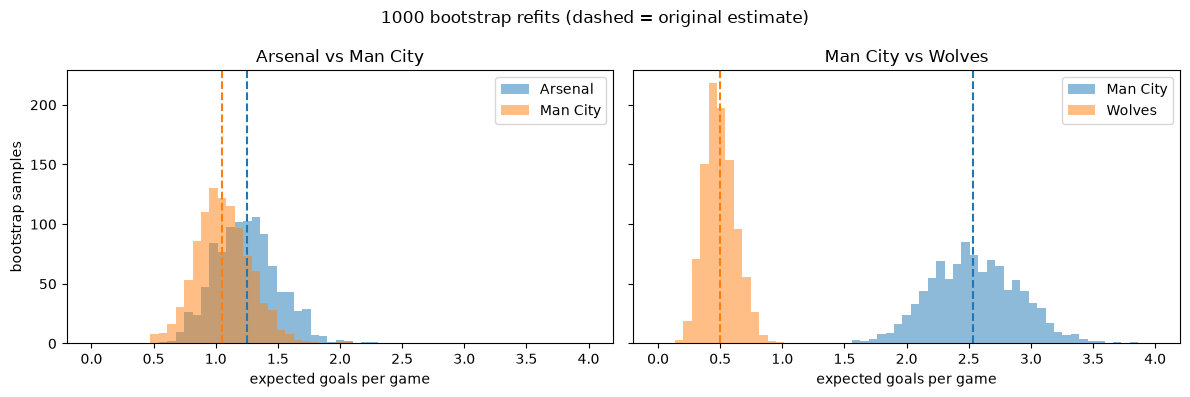

In [10]:
rows = []
for m, (a, h) in enumerate(matchups):
    for k, (team, opp) in enumerate([(a, h), (h, a)]):
        rows.append({"matchup": f"{a} vs {h}", "team": team,
                     "lambda-hat": lam_from_params(fit.params, team, opp),
                     "2.5%": np.percentile(boot[:, m, k], 2.5), "97.5%": np.percentile(boot[:, m, k], 97.5)})
    rows[-2]["P(this team's lambda is bigger)"] = (boot[:, m, 0] > boot[:, m, 1]).mean()
    rows[-1]["P(this team's lambda is bigger)"] = (boot[:, m, 1] > boot[:, m, 0]).mean()
print(pd.DataFrame(rows).set_index(["matchup", "team"]).round(3))

fig, axes = plt.subplots(1, len(matchups), figsize=(6 * len(matchups), 4), sharey=True)
bins = np.linspace(0, 4, 60)
for ax, m, (a, h) in zip(axes, range(len(matchups)), matchups):
    for k, team, opp in [(0, a, h), (1, h, a)]:
        ax.hist(boot[:, m, k], bins=bins, alpha=0.5, color=f"C{k}", label=team)
        ax.axvline(lam_from_params(fit.params, team, opp), color=f"C{k}", ls="--")
    ax.set_title(f"{a} vs {h}"); ax.set_xlabel("expected goals per game"); ax.legend()
axes[0].set_ylabel("bootstrap samples")
fig.suptitle(f"{B} bootstrap refits (dashed = original estimate)")
plt.tight_layout()
plt.show()

**Answer.** - **Arsenal vs Man City:** 1.25 vs 1.05 expected goals, with 95% intervals of about (0.78, 1.74) and (0.65, 1.50). These overlap almost completely. Arsenal's $\lambda$ is bigger in about 73% of the bootstrap samples, so the answer to **3** is a lean, not a confident call.
- **Man City vs Wolves:** 2.54 vs 0.50, with intervals of about (1.89, 3.23) and (0.28, 0.76). These don't overlap, and Man City's $\lambda$ is bigger in all 1,000 samples.
- **Narrower or further apart?** Further apart. The intervals aren't narrower (Man City's is the widest), but the gap is now much bigger than the uncertainty.
- Being sure who has the bigger $\lambda$ isn't the same as being sure who wins one match. A single game is still a noisy Poisson draw (see **4**).